In [ ]:
# --- Install necessary packages (run in notebook or Colab) ---
# !pip install hmmlearn yfinance python-binance --quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from utils import fetch_binance_data
import yfinance as yf

from binance.client import Client
from typing import Union, Optional
from datetime import datetime
from binance.enums import HistoricalKlinesType

In [ ]:
def fetch_binance_data(
    symbol: str,
    interval: str = '1d',
    years: int = 10,
    start_time: Union[str, int] = '',
    end_time: Union[str, int] = '',
    kline_type: str = 'spot'
) -> pd.DataFrame:
    
    if years or (start_time == '' and end_time == ''):
        start_time = (datetime.now() - pd.Timedelta(days=365*years)).strftime('%Y-%m-%d %H:%M:%S')
        end_time = datetime.now().strftime('%Y-%m-%d %H:%M:%S')

    if kline_type == 'spot':
        t = HistoricalKlinesType.SPOT
    else:
        t = HistoricalKlinesType.FUTURES

    klines = Client(None, None).get_historical_klines(
        symbol=symbol,
        interval=interval,
        start_str=start_time,
        end_str=end_time,
        klines_type=t
    )

    cols = [
        "open_time", "open", "high", "low", "close", "volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base", "taker_buy_quote", "ignore"
    ]

    df = pd.DataFrame(klines, columns=cols)
    df[["open", "high", "low", "close", "volume"]] = df[["open", "high", "low", "close", "volume"]].astype(float)
    df["open_time"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    df = df[["open_time", "open", "high", "low", "close", "volume"]]

    return df

In [ ]:
# --- 1. Load and Align Data ---
BTC = fetch_binance_data('BTCUSDT', kline_type='futures', interval='1d', years=5).set_index('open_time')
BTC_DOM = fetch_binance_data('BTCDOMUSDT', kline_type='futures', interval='1d', years=5).set_index('open_time')
PAXG_raw = yf.download('XAUT-USD', period='max').T.droplevel(1).T

# Fix timestamps
PAXG_raw.index = pd.to_datetime(PAXG_raw.index, utc=True)
PAXG = PAXG_raw[['Open', 'High', 'Low', 'Close', 'Volume']]
PAXG.columns = ['open', 'high', 'low', 'close', 'volume']

# Align all to BTC_DOM index
BTC = BTC.reindex(BTC_DOM.index)
PAXG = PAXG.reindex(BTC_DOM.index)

# --- 2. Compute Daily Returns ---
returns = pd.DataFrame({
    'BTC': BTC['close'].pct_change(),
    'BTC_DOM': BTC_DOM['close'].pct_change(),
    'PAXG': PAXG['close'].pct_change()
}).dropna()

scale_factor_paxg = returns.std()['BTC_DOM'] / returns.std()['PAXG']
returns['PAXG'] = returns['PAXG'] * scale_factor_paxg

# --- 3. Kelly Scaling (Optional) ---
btc_vol_long = returns['BTC'].rolling(360).std() * np.sqrt(360) / 2
btc_vol_short = returns['BTC'].rolling(30).std() * np.sqrt(360)
kelly_weight = (btc_vol_long / btc_vol_short).clip(0.2, 0.8).fillna(method='bfill')
kelly_weight = kelly_weight.resample('M').interpolate(limit_direction='both')
kelly_weight = kelly_weight.reindex(returns.index).fillna(method='ffill').fillna(0.5)

[*********************100%***********************]  1 of 1 completed
<ipython-input-6-8721837253e9>:28: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  kelly_weight = (btc_vol_long / btc_vol_short).clip(0.2, 0.8).fillna(method='bfill')
<ipython-input-6-8721837253e9>:29: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  kelly_weight = kelly_weight.resample('M').interpolate(limit_direction='both')
<ipython-input-6-8721837253e9>:30: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  kelly_weight = kelly_weight.reindex(returns.index).fillna(method='ffill').fillna(0.5)


In [ ]:
# --- 4. Utility: Sharpe-optimal weights ---
from scipy.optimize import minimize
def get_max_sharpe_weights(mean_ret, cov):
    n = len(mean_ret)
    inv_cov = np.linalg.pinv(cov)
    
    # Objective: maximize Sharpe ratio = mean_ret.T @ w / sqrt(w.T @ cov @ w)
    # To minimize negative Sharpe ratio
    def neg_sharpe(w):
        port_return = w @ mean_ret
        port_vol = np.sqrt(w @ cov @ w)
        # Avoid division by zero
        if port_vol == 0:
            return 1e6
        return - port_return / port_vol
    
    # Initial guess: equal weights
    x0 = np.ones(n) / n
    
    # Bounds for each weight: [-1, 1]
    bounds = [(0.25, 1) for _ in range(n)]
    
    # Constraint: weights sum to 1
    cons = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    
    result = minimize(neg_sharpe, x0, bounds=bounds, constraints=cons)
    
    if result.success:
        return result.x
    else:
        # fallback to equal weights if optimization fails
        return x0

In [ ]:
# --- 5. Strategy: Dynamic HMM predicting next regime ---
rebalance_period = 90  # days
asset_cols = ['BTC', 'BTC_DOM', 'PAXG']

strategy_returns = []
regimes = []
last_weights = None
last_next_state = np.nan

# Prepare a DataFrame to hold weights with NaNs initially
weights_df = pd.DataFrame(np.nan, index=returns.index, columns=asset_cols)

for t in range(1, len(returns)):
    if t % rebalance_period == 0:
        train_data = returns[asset_cols].iloc[:t].copy()

        # Train HMM
        model = GaussianHMM(n_components=3, covariance_type="diag", n_iter=1500, random_state=42)
        model.fit(train_data)

        train_states = model.predict(train_data)
        train_data['Regime'] = train_states

        current_state = train_states[-1]

        transmat = model.transmat_
        next_state_prob = transmat[current_state]
        next_state = np.argmax(next_state_prob)
        last_next_state = next_state

        regime_means = train_data.groupby('Regime').mean()
        regime_covs = train_data.groupby('Regime').cov()

        mu = regime_means.loc[next_state].values
        cov = regime_covs.loc[next_state].values.reshape(len(mu), len(mu))

        last_weights = get_max_sharpe_weights(mu, cov)

        # Save weights at rebalance time t
        weights_df.iloc[t] = last_weights

    if last_weights is None:
        last_weights = np.ones(len(asset_cols)) / len(asset_cols)

    ret = returns.iloc[t][asset_cols].values @ last_weights
    strategy_returns.append(ret)
    regimes.append(last_next_state)

Model is not converging.  Current: 636.2412512155721 is not greater than 636.3937149689231. Delta is -0.15246375335095763
Model is not converging.  Current: 1283.4640567517472 is not greater than 1283.4963741493455. Delta is -0.03231739759826269
Model is not converging.  Current: 1947.044366964812 is not greater than 1947.0497150866906. Delta is -0.005348121878569145
Model is not converging.  Current: 2588.5490439449354 is not greater than 2588.6947421296545. Delta is -0.14569818471909457
Model is not converging.  Current: 3262.0377788753303 is not greater than 3262.07407061889. Delta is -0.03629174355955911
Model is not converging.  Current: 3941.1708555117066 is not greater than 3941.2039230791142. Delta is -0.03306756740767014
Model is not converging.  Current: 4676.850615819332 is not greater than 4676.881035108558. Delta is -0.030419289225392276
Model is not converging.  Current: 6942.75510852754 is not greater than 6942.772016557255. Delta is -0.016908029714613804
Model is not co

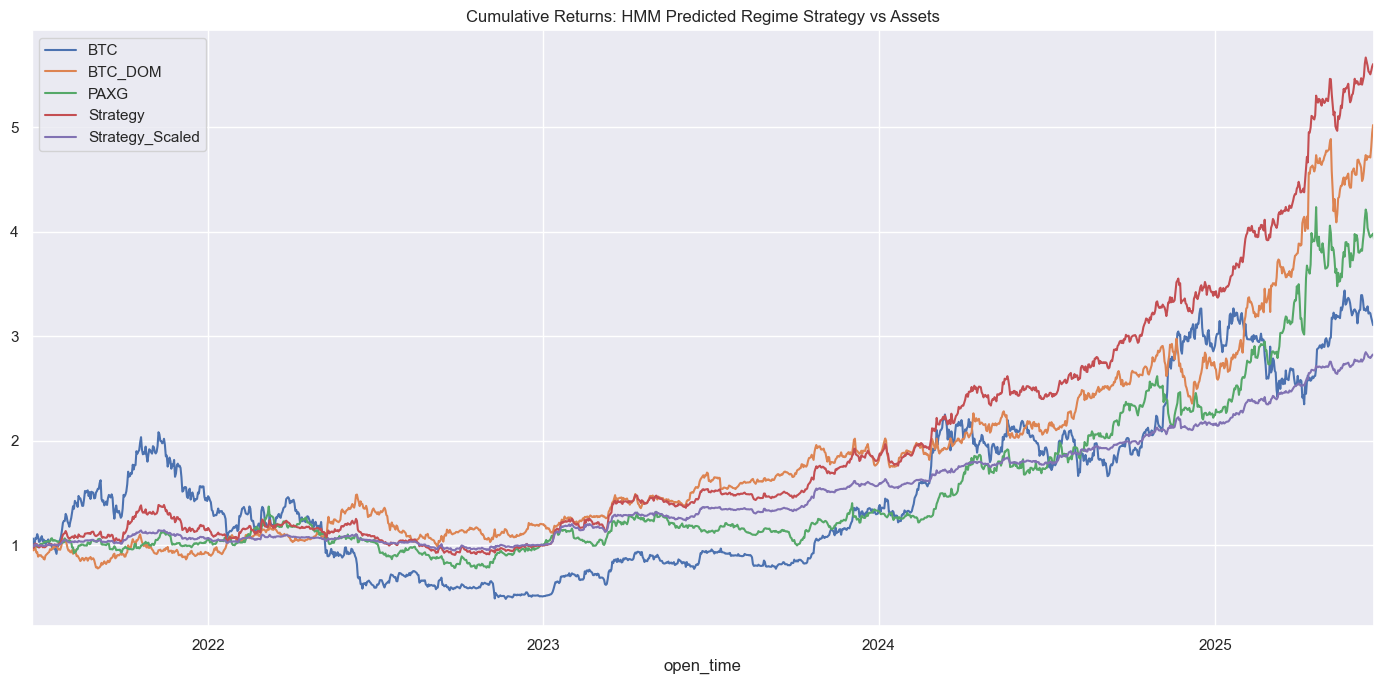

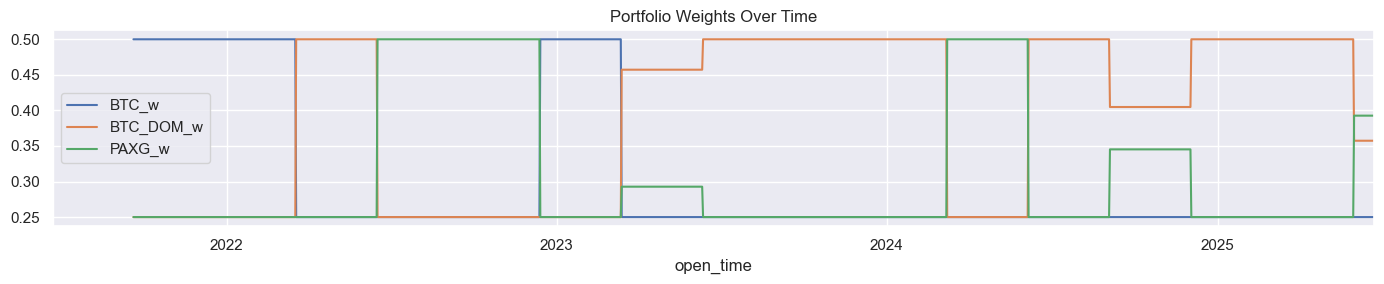

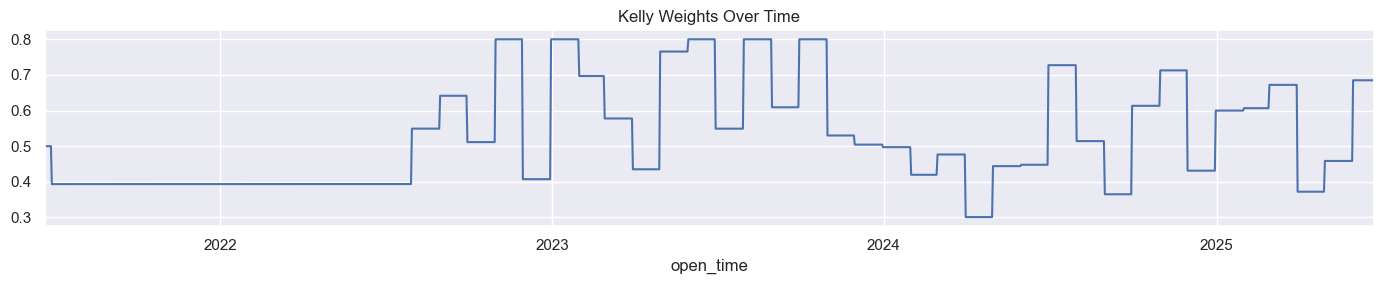

In [ ]:
# --- 6. Align results ---
returns = returns.iloc[1:].copy()  # align length with returns used for strategy
returns['Strategy'] = strategy_returns
returns['Predicted_Next_Regime'] = regimes

# Forward-fill weights to all days between rebalances
weights_df = weights_df.add_suffix('_w')  # now columns are BTC_w, BTC_DOM_w, PAXG_w
weights_df = weights_df.ffill().iloc[1:]
returns = returns.join(weights_df)

returns['Strategy_Scaled'] = returns['Strategy'] * kelly_weight.iloc[1:].values

# --- 7. Plot cumulative returns ---
cumulative = (1 + returns[asset_cols + ['Strategy', 'Strategy_Scaled']]).cumprod()
sns.set(style="darkgrid")
cumulative.plot(figsize=(14, 7), title="Cumulative Returns: HMM Predicted Regime Strategy vs Assets")
plt.grid(True)
plt.tight_layout()
plt.show()

# Optional: plot weights over time
weights_df.plot(figsize=(14,3), title="Portfolio Weights Over Time")
plt.grid(True)
plt.tight_layout()
plt.show()

# Optional: plot weights over time
kelly_weight.plot(figsize=(14,3), title="Kelly Weights Over Time")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# --- 8. Performance summary ---
def summary_stats(ret_series, freq=365):
    ann_return = ret_series.mean() * freq
    ann_vol = ret_series.std() * np.sqrt(freq)
    sharpe = ann_return / ann_vol if ann_vol != 0 else np.nan
    return pd.Series({
        'Annual Return': round(ann_return, 4),
        'Annual Volatility': round(ann_vol, 4),
        'Sharpe Ratio': round(sharpe, 4)
    })

print("Performance Summary (Annualized):\n")

assets_to_compare = ['BTC', 'BTC_DOM', 'PAXG', 'Strategy', 'Strategy_Scaled']
summary_table = pd.DataFrame({col: summary_stats(returns[col]) for col in assets_to_compare})

# Transpose for readability
summary_table = summary_table.T
print(summary_table.round(4))

Performance Summary (Annualized):

                 Annual Return  Annual Volatility  Sharpe Ratio
BTC                     0.4387             0.5543        0.7914
BTC_DOM                 0.4583             0.3353        1.3667
PAXG                    0.3982             0.3356        1.1865
Strategy                0.4612             0.2524        1.8274
Strategy_Scaled         0.2672             0.1308        2.0429
